# 5. Fix the OSM data once

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/05_osm_fixes.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/05_osm_fixes.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-5.svg" alt="duckOSM notebook manual, chapter 5: Fix the OSM data once" width="100%">

| **You learn** | what a fixes file is and its format; three ways to make it: the editing page, Python and a text editor; a build again with `net.rebuild` and a new build with the file; how you check the fix; which fixes keep the `edge_id` |
|---|---|
| **Time** | about 4 minutes |
| **Extras** | `duckosm[widget,viz]` (the install cell installs them) |
| **Next** | [6. Exports](06_exports.md): the network as SUMO, MATSim, GMNS, OpenDRIVE and GIS files |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## Why you fix the OSM data

OpenStreetMap is a map that people make. It is very good, but it has errors: a speed limit that is old, a road that
is one-way in the real world but not in OSM, a wrong number of lanes, a road that is closed for road works. When you
find such an error, you have three choices:

| Choice | The result |
|---|---|
| Correct OSM itself on [openstreetmap.org](https://www.openstreetmap.org) | correct for everyone, but your next extract has it only after the next Geofabrik update, and some changes (road works, a test scenario) do not belong in OSM |
| Correct each output by hand (the SUMO file, the GIS file, the database) | each output needs its own work, and the next build loses it |
| Write the fix in a **fixes file** that duckOSM reads | you write it one time, and each build and each export takes it |

duckOSM uses the third choice. A **fixes file** (`osm_fixes.yaml`) holds your corrections as **rules**. Each rule names
one OSM way by its id and says what to change. The build reads the file before it makes the networks. So the
database, the map, the routes and every export show the corrected data.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/fixes-flow.svg" alt="The fixes file goes into the build; the network and every export take the fix" width="100%">

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> You fix the OSM data, not the outputs. The fixes file is the one place for your corrections, and every output of the build takes them. The next build, with a new extract, takes them again.

## The format of the file

### What the file holds

A fixes file is a list of your corrections of the OSM data. It puts the corrections in groups, one group for each kind
of correction:

| Group | Holds |
|---|---|
| `overrides` | the rules for OSM ways: change the tags, one-way or lanes of a way, or remove the way |
| `new_ways` | the roads that OSM does not have |
| `turn_restrictions` | the turns that a driver cannot make, or must make |
| `extra` → `tag_edits` | the changes of the tags of a node, a way or a relation |
| `extra` → `building_faces` | the type and the door of each wall of a building |

The file is in YAML, a text format. You can read it in any text editor.

### YAML in three rules

**1. `key: value` is one field.**

```yaml
osm_id: 4230891
```

**2. A line that starts further right belongs to the line above it.**

```yaml
tags:
  maxspeed: '10'
```

`maxspeed` has two spaces more than `tags`, so `maxspeed` is inside `tags`: it is a tag of the way.

**3. A line that starts with `- ` (a dash and a space) begins a new item of a list.**

```yaml
overrides:
- osm_id: 4230891
- osm_id: 4230100
```

Here `overrides` holds a list of two items. The lines under an item, with two spaces more than its dash, belong to that
item.

YAML uses the spaces at the start of a line to show what is inside what, as Python does. Use spaces, never the Tab key.

### The skeleton of a fixes file

Each group is one key at the start of a line, and each key holds a list. This is a fixes file with five empty lists
(`[]` is an empty list):

```yaml
overrides: []
new_ways: []
turn_restrictions: []
extra:
  tag_edits: []
  building_faces: []
```

You need only the groups that you use. A file with only `overrides` is a correct file.

### Build the file step by step

**Step 1: one rule.** Road works on Boulevard Louis II, the OSM way 4230891, lower its speed limit to 10 km/h. The rule
names the way and sets its tag `maxspeed`:

```yaml
overrides:
- osm_id: 4230891
  tags:
    maxspeed: '10'
  note: road works
```

The build now sees the way as if OSM had `maxspeed=10`. The `note` is your text. The build does not read it.

**Step 2: a second rule.** Way 4230100 is one-way in the real world. Add a new item under the same `overrides:`:

```yaml
overrides:
- osm_id: 4230891
  tags:
    maxspeed: '10'
  note: road works
- osm_id: 4230100
  oneway: true
```

**Step 3: remove a way.** Way 4229578 does not exist in the real world. A rule with `remove: true` takes it out of the
build: out of the network, the base map and every export. Add it as one more item:

```yaml
- osm_id: 4229578
  remove: true
```

To take a way out of some networks only, use `exclude_modes`. For example, a street that is closed to cars but open
to people on foot:

```yaml
- osm_id: 4229577
  exclude_modes:
  - driving
```

**Step 4: the other groups.** Each group has its own list. A new road, a forbidden turn and a traffic signal on a node
are one item in each of three lists:

```yaml
new_ways:
- id: 9000000000000
  nodes:
  - 21911886
  - [7.4235072, 43.7371133]
  - 21914340
  tags:
    highway: service
    name: New lane
turn_restrictions:
- from_way: 4230100
  via_node: 21924057
  to_way: 4230099
  restriction: no_left_turn
extra:
  tag_edits:
  - type: node
    id: 21924057
    set:
      highway: traffic_signals
```

### The rules of the file

- **Each group comes one time.** The file has one `overrides:`, one `new_ways:`, one `turn_restrictions:` and one
  `extra:`. Do not write a second `overrides:` for a new rule: YAML keeps only the last one, and the rules of the
  first one are lost with no error.
- **To add a record, add an item to the list of its group.**
- **One way has one rule.** To change more on a way, add fields to its rule. Do not add a second item with the same
  `osm_id`.
- **To remove a fix, delete its item**, from its `- ` line to the end of the record. The way is then as in OSM again.
- **The spaces must agree.** All the items of one list have their dash at the same position, and all the fields of
  one record start at the same position.
- **Write the value of a tag in quotes**, for example `maxspeed: '10'`, because an OSM tag is text.
- **A record for an object that is not in the area does nothing.** So one file can hold the fixes of all your areas.

You can also write a record on one line, in braces: `- {osm_id: 4230100, oneway: true}`. It has the same meaning as
the long form. `Fixes` and the editing page write the long form, and they follow all these rules for you.

### The full example

This file has one record of each kind. It is the result of the four steps, and a reference for your own file:

```yaml
overrides:
- osm_id: 4230891
  tags:
    maxspeed: '10'
  note: road works
- osm_id: 4230100
  oneway: true
- osm_id: 503462470
  lanes: 3
  turn_lanes_forward: left|through|through
- osm_id: 4229577
  exclude_modes:
  - driving
- osm_id: 4229578
  remove: true
new_ways:
- id: 9000000000000
  nodes:
  - 21911886
  - [7.4235072, 43.7371133]
  - 21914340
  tags:
    highway: service
    name: New lane
turn_restrictions:
- from_way: 4230100
  via_node: 21924057
  to_way: 4230099
  restriction: no_left_turn
extra:
  tag_edits:
  - type: node
    id: 21924057
    set:
      highway: traffic_signals
  - type: relation
    id: 393226
    delete:
    - building
  building_faces:
  - building: 23715051
    from_node: 256791677
    to_node: 256791676
    type: front
    door: main
```

The editing page also adds `changed`, the time of the change, to each record. The build does not read it.

### The fields of each group

**`overrides`**: one rule for one OSM way.

| Field | Does |
|---|---|
| `osm_id` | the OSM id of the way (the key of the rule) |
| `tags` | sets these OSM tags on the way (`maxspeed`, `highway`, `name`, `surface` ...) |
| `oneway` | `true` or `false` |
| `lanes`, `lanes_forward`, `lanes_backward` | the lanes in both directions, or in one direction |
| `turn_lanes_forward`, `turn_lanes_backward` | the arrows of the lanes, in the syntax of the OSM tag `turn:lanes` |
| `layer` | the vertical level (a bridge is 1, a tunnel is -1) |
| `keep_nodes` | `[from, to]`: keep only this part of the way |
| `exclude_modes` | removes the way from these networks only: `driving`, `walking`, `cycling` |
| `remove` | `true`: removes the way from the whole build |
| `note` | your text: why you made the fix. The build does not read it |

**`new_ways`**: one new road.

| Field | Does |
|---|---|
| `id` | 9,000,000,000,000 or more, used one time. Do not change it: the edge ids come from it |
| `nodes` | the points of the road: an OSM node id, or `[lon, lat]` for a new point. Make the two ends OSM nodes, so that the road connects to the network |
| `tags`, `tags_from` | the OSM tags of the road, or the OSM way to copy the tags from |

**`turn_restrictions`**: one turn. A turn restriction changes the driving network.

| Field | Does |
|---|---|
| `from_way`, `via_node`, `to_way` | the way before the junction, the node of the junction and the way after it |
| `restriction` | `no_u_turn` (the default), `no_left_turn`, `no_right_turn`, `no_straight_on`, or `only_left_turn`, `only_right_turn`, `only_straight_on` |

**`extra`**: the tags of other objects, and the walls of buildings.

| Record | Fields |
|---|---|
| `tag_edits` | `type` (`node`, `way` or `relation`), `id`, and `set` (the tags to set) or `delete` (the tags to delete) |
| `building_faces` | `building`, `from_node` and `to_node` (the wall), `type` (`front`, `back`, `side`, `party` or `court`) and `door` |

A node and a relation have no `remove`. To take one out, delete the tag that makes it what it is. For example, a
relation without the tag `building` is no longer a building.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes and saves it as `monaco.duckdb`, with no fixes file. This network is the
"before" of the chapter. `net.save` put the OSM file `monaco.osm.pbf` and the boundary `monaco.geojson` beside it. A
fix needs these two files, because the build with the fix starts again from the OSM data.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes, no fixes file
net                                    # the card

Network('monaco.duckdb', 50.3 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

The card shows the file `monaco.duckdb` and its three networks: the number of
edges and nodes and the length in km of each mode. This is the network before the fix.

## Make the file and add records

There are three ways to make a fixes file and to add records to it. All three write the same format, so you can use
them together on one file.

| Way | Use it when | You need the OSM id? |
|---|---|---|
| the editing page, `net.edit()` | you want to click the road on a map | no: you click the road |
| Python, `duckosm.fixes.Fixes` | you fix many roads from a list, or in a script | yes |
| a text editor | you want to read or change the file yourself | yes |

### The editing page: `net.edit()`

The easiest way is the editing page. You find a road on a map, change it in a form, and the page writes the record
into the fixes file. It is also the only way for some fixes: a turn that a driver cannot make, a new road, the walls of
a building. `net.edit()`
starts the editor **Edit OSM data** on the database, on your computer. The page shows the roads and the buildings of
the area on a map. Each change that you add on the page goes into the fixes file at once, in the same format as
`Fixes`.

`net.edit()` starts the page in the background and gives its address. Open the address in your browser:

```python
net.edit()
```

```text
'http://127.0.0.1:8790/'
```

The page writes the fixes file of the build. A network with no fixes file gets `osm_fixes.yaml` beside its database.
To write another file, or to use another port, give them to `net.edit()`:

```python
net.edit(fixes="osm_fixes.yaml", port=8791)
```

| Argument | Default | Does |
|---|---|---|
| `fixes` | the fixes file of the build, else `osm_fixes.yaml` beside the database | the file that the page writes |
| `port` | `8790` | the port of the page on `127.0.0.1` |

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/edit-road.png" alt="The editing page: Boulevard Charles III is picked in the Road tab, and its lanes are changed to 3" width="100%">

The page has one tab for each kind of record:

| Tab | What you change | Key in the file |
|---|---|---|
| **Road** | the tags of a road (class, lanes, speed, one-way, sidewalk, surface, access); delete the road | `overrides`, `extra.tag_edits` |
| **Building** | floors, height, roof, facade; the type of each wall and its door; delete the building | `extra.tag_edits`, `extra.building_faces`, `overrides` |
| **Node** | a traffic signal, a crossing or another node | `extra.tag_edits` |
| **Turn** | a turn that a driver cannot make, or must make, at a junction | `turn_restrictions` |
| **New road** | a road that OSM does not have: click its points on the map | `new_ways` |
| **Changes** | the list of your changes, and **Build again** | |

To add one record:

1. Pick a tab.
2. Click the road on the map, or type its OSM id and click **Load**.
3. Change the fields, then click **Add to changes**. The page writes the record into the file at once.
4. In the **Changes** tab, click **Build again** to build the network again with the file.

In the **Turn** tab, you pick a road, and the page shows the roads at its junction: the picked road (**From**) is
blue, the roads that leave the junction are green, and the roads that only arrive are violet. You then choose the
turn that a driver cannot make, or must make.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/edit-turn.png" alt="The Turn tab: the picked road is blue, the roads that leave the junction are green and the road that only arrives is violet" width="100%">

The editor runs while Python runs. The guide [Fix the OSM data](../guides/edit-osm-data.md) shows each tab and
button of the page.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> The page is on `127.0.0.1` of the machine that runs Python. In Colab, that machine is in the cloud, so your browser cannot open the page. Run `net.edit()` in Jupyter on your own computer, or use the step **Edit OSM data** of [duckOSM Studio](https://khoshkhah.github.io/duckosm-studio/) in the browser.

### From Python: `duckosm.fixes.Fixes`

`duckosm.fixes.Fixes(path)` opens a fixes file, or makes a new one when the file does not exist. Each call that adds a
rule writes the file at once, so the file on disk is always the same as the object in Python.

`fixes.set(way, **fields)` adds a rule for the way, or changes its rule. A keyword that is a field of a rule (`oneway`,
`lanes`, `layer`, `note` ...) goes into the rule. Each other keyword is an OSM tag: `maxspeed=10` sets the tag
`maxspeed` to `"10"`. The build then reads the tag as OSM data, so the speed and the travel time of the road change.

The fix of this chapter: road works on Boulevard Louis II, the OSM way 4230891, lower its speed limit to
10 km/h.

In [3]:
way = 4230891                                          # Boulevard Louis II: the OSM way to fix
fixes = duckosm.fixes.Fixes("osm_fixes.yaml")          # open or make the fixes file
fixes.set(way=way, maxspeed=10, note="road works")     # one rule: the tag maxspeed of the way, and a note
fixes                                                  # the card: a table of the rules

osm_id,tags,note
4230891,{'maxspeed': '10'},road works


The card names the file and the number of rules (1). The table has one row for
each way: `osm_id`, the OSM `tags` of the rule (`maxspeed` is the text `'10'`) and the `note`.

The file is ordinary YAML. You can read it, keep it in git with your project, and give it to a colleague.

In [4]:
print(open("osm_fixes.yaml").read())    # the fixes file on disk

overrides:
- osm_id: 4230891
  tags:
    maxspeed: '10'
  note: road works



The rule is one item of `overrides`: the `osm_id`, the `tags` with `maxspeed` and
the `note`. This is the format that the map editor writes, so the two tools can share one file.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> `Fixes` writes the whole file again at each change. Comments that you wrote in the file by hand are lost. The other keys of the file (`new_ways`, `turn_restrictions`, `extra`) stay.

#### The other calls

`set` is one of five calls that change the rules. The table shows all of them. Each call returns the `Fixes`, so you
can chain the calls.

| Call | Does | The field in the file |
|---|---|---|
| `fixes.set(way, **fields)` | sets the fields and the OSM tags of the way | the fields, and `tags` |
| `fixes.exclude(way, modes)` | removes the way from the networks of `modes` only | `exclude_modes` |
| `fixes.remove(way)` | removes the way from the whole build: no road, no building, no feature | `remove: true` |
| `fixes.drop(way)` | deletes the rule of the way, so the way is as in OSM again | the rule is gone |
| `fixes.rules()` | gives the rules as a DataFrame | |

The cell below tries each call on a second file, `practice.yaml`, so the file of the chapter keeps its one rule. Two
other roads of Monaco get a rule each.

In [5]:
w2, w3 = 503633031, 166399479                              # Avenue Princesse Grace and Boulevard Albert 1er
practice = duckosm.fixes.Fixes("practice.yaml")              # a second fixes file
practice.set(way=w2, oneway=True, lanes=2)                   # two fields of a rule: one-way, two lanes
practice.set(way=w2, highway="residential")                  # an OSM tag; the rule of w2 keeps its fields
practice.exclude(way=w3, modes=["driving"])                  # no cars on w3; walking and cycling keep it
practice.rules()                                             # one row for each way, one column for each field

,osm_id,exclude_modes,remove,oneway,lanes,tags
0,166399479,[driving],True,NaN,NaN,NaN
1,503633031,NaN,NaN,True,2.0,{'highway': 'residential'}


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The table has two rows, one for each way. The second `set` on the same way did not make a new rule: it added the tag `highway` to the rule of `w2`, and `oneway` and `lanes` stay. The rule of `w3` has only `exclude_modes`.

In [6]:
practice.remove(way=w3)        # remove w3 from the whole build
practice.drop(way=w2)          # w2 is as in OSM again
practice, len(practice)        # the file now has one rule

(Fixes('practice.yaml', 1 rules), 1)

After `drop`, the file has one rule: the rule of `w3`, with `exclude_modes` and now
also `remove: true`. `len(fixes)` is the number of rules.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> `remove` and `exclude` are the two ways to take a road out. Use `exclude` for a road that some modes can use (a street that is closed to cars but open to people on foot). Use `remove` for a way that must not be in the data at all.

### In a text editor

The file is plain text, so you can also write it yourself in any text editor, in the format of section "The format of
the file". The cell below writes a file `hand.yaml` with one rule from Python, as a text editor would. Then `Fixes`
opens it and shows its rule: the file is the same as a file that `Fixes` or the editing page writes.

In [7]:
from pathlib import Path

Path("hand.yaml").write_text("""overrides:
  - osm_id: 4230891
    tags:
      maxspeed: "10"
    note: road works
""")                                                     # the file, written as text
duckosm.fixes.Fixes("hand.yaml").rules()               # open it: one rule

,osm_id,tags,note
0,4230891,{'maxspeed': '10'},road works


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> YAML uses the spaces at the start of each line. Keep two spaces for each level, as in the example, and write a number in a tag in quotes (`"10"`), because an OSM tag is text.

## Build with the fixes

A fixes file changes nothing by itself. A build reads it. There are two ways to build with the file.

| Way | Uses | Use it when |
|---|---|---|
| `net.rebuild(fixes=...)` | the same OSM file and boundary as `net` | you want to compare the network before and after the fix |
| a new build: `duckosm.network(..., fixes=...)` | a new extract, or another area | you build later with newer OSM data, or in another project |

### Build again: `net.rebuild`

`net.rebuild(fixes=...)` builds the area again, with the same modes, from the OSM file and the boundary beside the
database. It takes a `Fixes` or the path of a fixes file. The new network goes to `<name>_fixed.duckdb` beside the old
one (`out=` sets another file), so the old network stays and you can compare the two. To see the effect of the
fix, the cell compares one route by car across Monaco, from Fontvieille to Larvotto, before and after the fix.

In [8]:
fixed = net.rebuild(fixes=fixes)                     # the same build, with the fixes file: monaco_fixed.duckdb
a, b = (7.4155, 43.7285), (7.4335, 43.7468)          # Fontvieille and Larvotto, as (lon, lat)
before = net.driving.route(a, b)                             # a route by car across Monaco, before the fix
after = fixed.driving.route(a, b)                            # the same route on the fixed network
round(before.time_s), round(after.time_s)            # the seconds before and after the fix

Output: ./monaco_fixed.duckdb

(229, 252)

The route now takes 252 s, not 229 s. It does not use Boulevard Louis II now: it
takes other streets around it. The new route is longer (3,302 m, not 2,939 m), but at 10 km/h the old way is slower.

The new network remembers its fixes file. `fixed.fixes` gives the `Fixes` of the build. `net.fixes` is `None`,
because `net` has no fixes file.

In [9]:
fixed.fixes, net.fixes        # the fixes file of each network

(Fixes('osm_fixes.yaml', 1 rules), None)

### A new build with the file

The same file works in each new build. Give it to `duckosm.network`, to `area.build` or to the command
`duckosm build --fixes osm_fixes.yaml`. The cell below builds Monaco again from the start, with the file, into a new
network. The route takes the same time as after `rebuild`, because the two builds read the same OSM data and the same
rule.

In [10]:
again = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco_with_fixes", fixes="osm_fixes.yaml")   # a new build with the file
round(again.driving.route(a, b).time_s)                       # the same time as after rebuild

cut with the fixes: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco_with_fixes-20261121-001941-d1ca/monaco_with_fixes.duckdb

252

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> Keep the fixes file with your project. When you build the area again next month, with a newer OSM extract, the same file corrects the new build. A rule whose way is not in the new data does nothing.

## Check the fix

Four checks show that the fix works: the compare of the two networks, the map, the edge ids and the outputs.

### Compare the two networks

`net.diff(other)` compares two networks edge by edge, by `edge_id`. It gives one row for each edge that is different:

| Column | Meaning |
|---|---|
| `mode` | the mode of the edge |
| `edge_id` | the edge |
| `change` | `added` (only in `other`), `removed` (only in `net`) or `changed` (in both, with other values) |
| `changed` | for a changed edge: the names of the columns with a new value |

`net.diff(fixed)` is the same as `duckosm.fixes.diff(net, fixed)`. `mode=` compares one mode only. DuckDB joins the
two files, so the comparison is fast also for a large area.

In [11]:
changes = net.diff(fixed, mode="driving")                     # the edges that are different in the fixed network
changes.change.value_counts()                 # the number of edges of each kind of change

change
changed    8
Name: count, dtype: int64

In [12]:
changes.head()                                # the first changed edges, with the columns that changed

,mode,edge_id,change,changed
0,driving,240162084728701473,changed,"[cost_s, maxspeed_kmh]"
1,driving,2049231210413078233,changed,"[cost_s, maxspeed_kmh]"
2,driving,2179780264819535765,changed,"[cost_s, maxspeed_kmh]"
3,driving,2306557708558841926,changed,"[cost_s, maxspeed_kmh]"
4,driving,6467283554817943757,changed,"[cost_s, maxspeed_kmh]"


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Eight edges changed. No edge was added or removed. The eight edges are the fixed way: Boulevard Louis II is a two-way road, so it has four edges in each direction. On each edge, two columns changed: `maxspeed_kmh` (now 10) and `cost_s`, the travel time, which the build calculates from the speed.

### See the change on a map

`fixed.map(routes=...)` draws routes on the network, each in its own color. The cell draws three lines: the route
before the fix, the route after the fix, and the fixed way (its edges, as a route). Run the cell to see the live map:
you can zoom, and click a road to see its columns. The manual page shows a picture of the map.

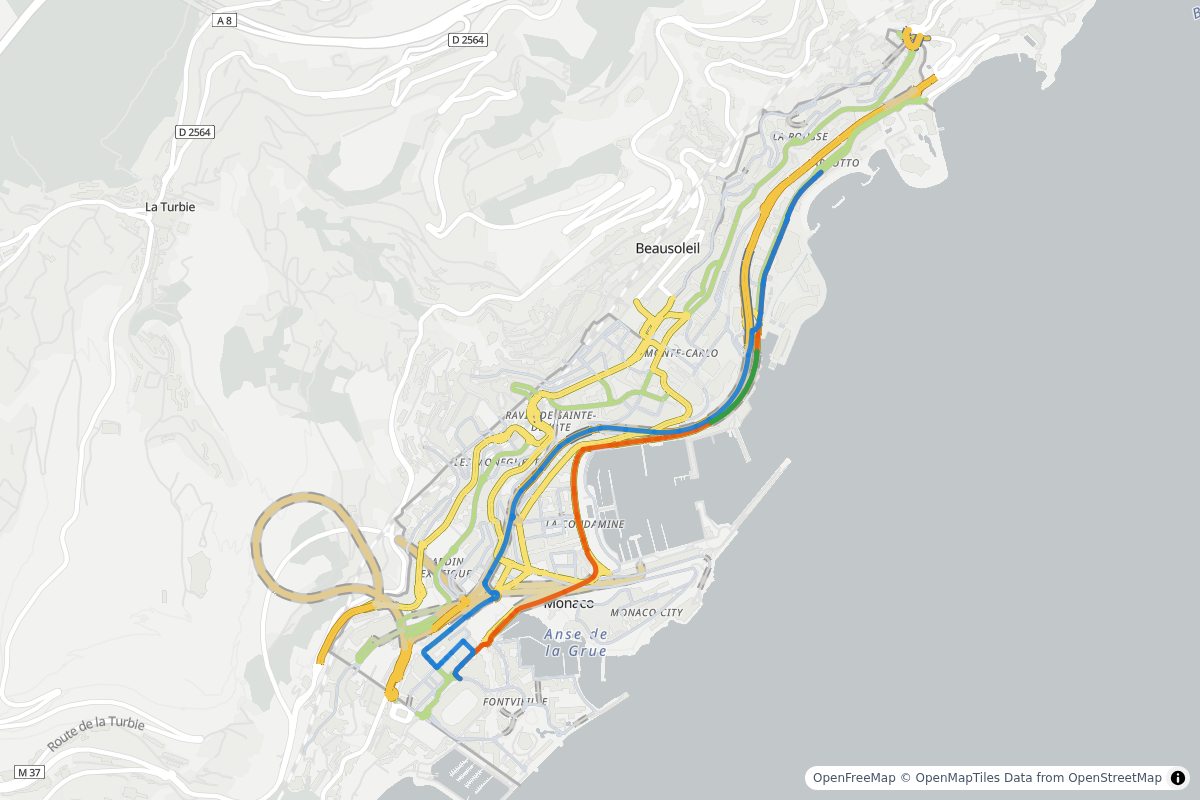

In [13]:
way_edges = {"edges": list(fixed.driving.edges(where=f"osm_id = {way}").edge_id)}                   # the edges of the fixed way, as a route to draw
fixed.driving.map(routes={"before the fix": before, "after the fix": after, "the fixed way": way_edges})    # the three as lines, each in its own color

The route after the fix leaves the fixed way. It takes other streets around the slow
part, because they are now faster.

### The edge ids do not change

An `edge_id` is a hash of the OSM way and of the two nodes at the ends of the edge. A fix of a tag (`maxspeed`,
`lanes`, `name`) does not change the way or its nodes. So each edge keeps its `edge_id`, and your own data that you
joined on the ids (chapter 4) stays correct after the fix.

In [14]:
set(net.driving.edges().edge_id) == set(fixed.driving.edges().edge_id)    # the same edge ids before and after the fix

True

`True`: the two networks have the same set of edge ids.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> A fix of the tags keeps every `edge_id`. A fix that removes a road (`remove`, `exclude`) removes the edges of that road only. All the other edges keep their ids.

#### A fix that removes a road

The next cell checks this rule. It closes the fixed way to cars with `exclude`, in a third file, and builds the area
again into `monaco_closed.duckdb` (`out=`).

In [15]:
closed = duckosm.fixes.Fixes("closed.yaml").exclude(way=way, modes=["driving"])    # no cars on the way
shut = net.rebuild(fixes=closed, out="monaco_closed.duckdb")                   # a third network
gone = net.diff(shut, mode="driving")                                                               # the edges that are different
gone.change.value_counts(), set(fixed.driving.edges(where=f"osm_id = {way}").edge_id) == set(gone.edge_id[gone.change == "removed"])

Output: ./monaco_closed.duckdb

(change
 removed    8
 Name: count, dtype: int64,
 True)

The diff has eight removed edges and no other change. The second value is `True`: the
removed edges are the eight edges of the fixed way. All the other edges of the network keep their ids.

### Every output takes the fix

The fix is in the network, so each export of the fixed network takes it: SUMO, MATSim, GMNS, OpenDRIVE and the GIS
files. The QuackOSM table reads the OSM file, and it takes the same fixes file with its own `fixes=`. Chapter 6 shows
these exports, and its last section reads the speed of Boulevard Louis II back from each output: 10 km/h in all of
them.

## Try it yourself

**1.** Make the fixed way one-way with `fixes.set(way=way, oneway=True)`, build again into a new file, and count the edges that `diff` gives as removed.

<details><summary>Show the answer</summary>

```python
fixes.set(way=way, oneway=True)                              # the rule of the way gets a field
oneway = net.rebuild(fixes=fixes, out="monaco_oneway.duckdb")
d = net.diff(oneway, mode="driving")
(d.change == "removed").sum()                                 # the edges of the other direction
```
</details>

**2.** Close Boulevard Albert 1er (`w3`) to cars only, and find the new time of the route.

<details><summary>Show the answer</summary>

```python
closed3 = duckosm.fixes.Fixes("closed3.yaml").exclude(way=w3, modes="driving")
net.rebuild(fixes=closed3, out="monaco_closed3.duckdb").driving.route(a, b).time_s     # about 252 s
```
</details>

**3.** Delete the rule of the fixed way, so that the way is as in OSM again, and look at the file.

<details><summary>Show the answer</summary>

```python
fixes.drop(way=way)
print(open("osm_fixes.yaml").read())                           # overrides: []
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| fix | a correction of the OSM data, written in a fixes file |
| fixes file | the YAML file of your fixes (`osm_fixes.yaml`); each build reads it |
| rule | one item of `overrides`: what to change on one OSM way |
| way | an OSM line (a road, a path); a way becomes one edge or more |
| `osm_id` | the id of the OSM way of an edge; the key of a rule |
| tag | an OSM key and value on a way, for example `maxspeed=30` |
| rebuild | a new build of the same area and modes, with a fixes file |
| diff | the edges that are added, removed or changed between two networks, by `edge_id` |

## Summary

| Call | Does |
|---|---|
| `duckosm.fixes.Fixes(path)` | opens or makes a fixes file |
| `fixes.set(way, **fields)` | adds or changes the rule of a way: fields of a rule and OSM tags |
| `fixes.exclude(way, modes)` | removes the way from the networks of `modes` |
| `fixes.remove(way)` | removes the way from the build |
| `fixes.drop(way)` | deletes the rule of the way |
| `fixes.rules()`, `len(fixes)` | the rules as a DataFrame, and their number |
| `net.rebuild(fixes=..., out=...)` | builds the area again with the fixes; gives the new `Network` |
| `net.fixes` | the `Fixes` of the build, or `None` |
| `net.diff(other, mode=None)`, `duckosm.fixes.diff(net, other)` | the edges that are different, by `edge_id` |
| `net.edit(fixes=None, port=8790)` | starts the editing page and gives its URL |
| `duckosm.network(..., fixes=...)`, `area.build(fixes=...)` | a new build with the fixes file |
| `duckosm.gis.quack(..., fixes=...)` | the QuackOSM table of the OSM file, with the fixes |

The reference: [duckosm.fixes](../reference/sdk/fixes.md). **Next:** [6. Exports](06_exports.md), the network as SUMO, MATSim, GMNS, OpenDRIVE and GIS files.